<a href="https://colab.research.google.com/github/njw257/bigdata/blob/main/week09_5685599_%EB%82%A8%EC%A2%85%EC%9A%B1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 9주차 과제
빅데이터프로그래밍 · 통계학과

**이름: 남종욱**
**학번:5685599**

## 과제 내용
3개 이상의 모델을 실험하고, 결과표와 가장 좋은 모델의 선택 이유를 제출합니다.

## 제출 방법
모든 셀을 실행해 출력과 그래프가 보이는 상태로 저장한 뒤 `week09_학번_이름.ipynb` 로 제출합니다.

**런타임 > 런타임 유형 변경 > T4 GPU** 를 먼저 선택하세요.


In [1]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import pandas as pd
import time

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

# 실험 조건 — 바꾸지 마세요
EPOCHS, BATCH, LR, N_TRAIN, SEED = 25, 64, 1e-3, 2000, 42

test_tf = transforms.ToTensor()
plain_train = datasets.FashionMNIST("./data", train=True,  download=True, transform=test_tf)
test_set    = datasets.FashionMNIST("./data", train=False, download=True, transform=test_tf)
plain_loader = DataLoader(Subset(plain_train, range(N_TRAIN)), batch_size=BATCH, shuffle=True)
test_loader  = DataLoader(test_set, batch_size=256, shuffle=False)

CLASSES = ["티셔츠", "바지", "풀오버", "드레스", "코트",
           "샌들", "셔츠", "운동화", "가방", "앵클부츠"]


device: cuda


100%|██████████| 26.4M/26.4M [00:02<00:00, 12.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 205kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.79MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 3.64MB/s]


## 공통 함수
아래를 그대로 쓰고 모델과 loader만 바꿔 실험하세요.


In [2]:
loss_fn = nn.CrossEntropyLoss()

def measure(model, loader):
    model.eval()
    loss_sum = correct = total = 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss_sum += loss_fn(out, y).item() * y.numel()
            correct += (out.argmax(dim=1) == y).sum().item()
            total += y.numel()
    return loss_sum / total, correct / total


def run(model, loader, epochs=EPOCHS, lr=LR, seed=SEED):
    torch.manual_seed(seed)
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    start = time.time()
    hist = []
    for epoch in range(1, epochs + 1):
        model.train()
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            loss = loss_fn(model(x), y)
            opt.zero_grad(); loss.backward(); opt.step()
        hist.append((*measure(model, plain_loader), *measure(model, test_loader)))
        if epoch % 10 == 0:
            print(f"  epoch {epoch}  검증 {hist[-1][3]:.4f}")
    return {"model": model, "hist": hist, "time": time.time() - start}


## 문제 1. 기본 CNN으로 과적합 확인 (20점)
규제 장치가 없는 CNN을 학습시키고 아래를 제출하세요.

- 학습 손실 · 검증 손실 · 학습 정확도 · 검증 정확도 곡선 (한 그림에 2×2)
- 검증 손실이 가장 낮았던 epoch
- 최종 학습-검증 정확도 차이


  epoch 10  검증 0.8425
  epoch 20  검증 0.8376


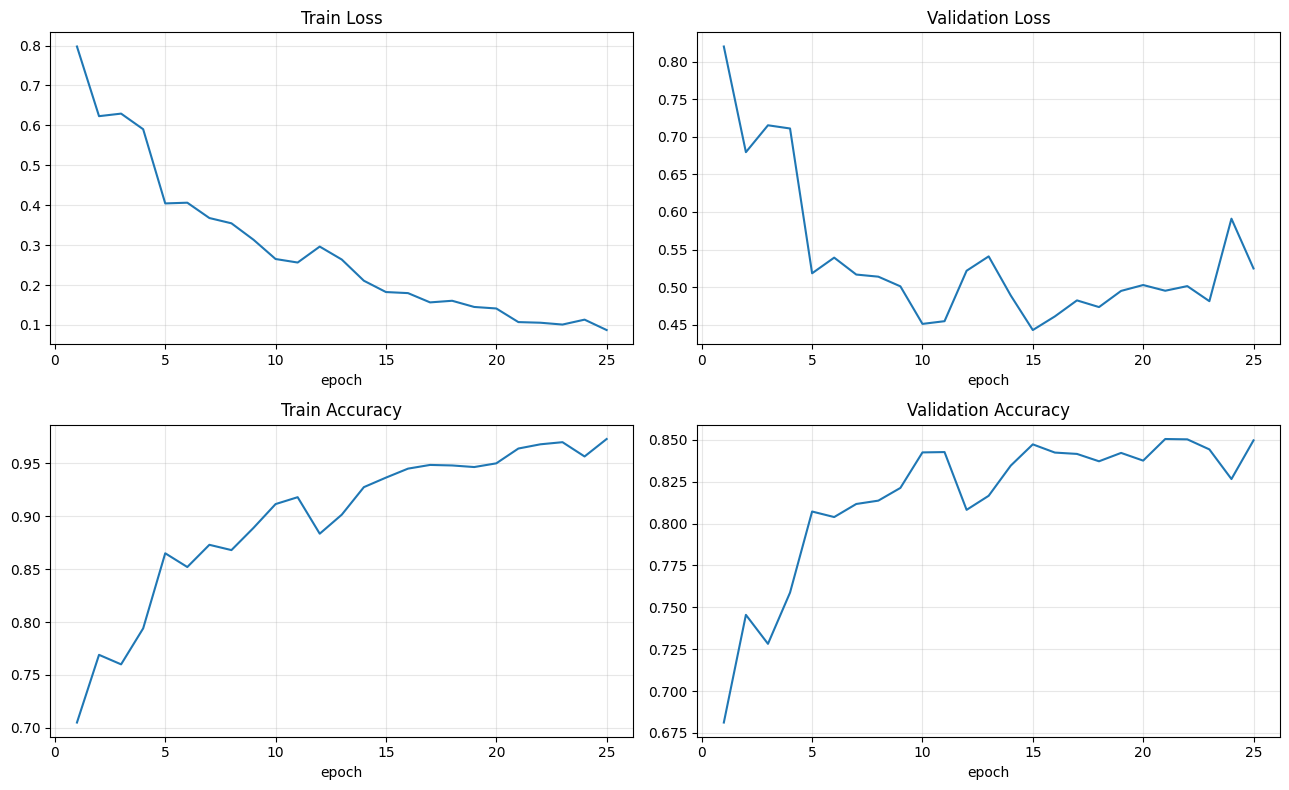

최저 검증 손실 epoch: 15
최종 학습-검증 정확도 차이: 0.1233


In [3]:
# 답안

# 기본 CNN 모델 정의
class PlainCNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64*7*7, 256), nn.ReLU(),
            nn.Linear(256, n_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


# 기본 CNN 학습
torch.manual_seed(SEED)
results = {}
results["기본 CNN"] = run(PlainCNN(), plain_loader)

# 학습 결과 정리
history = results["기본 CNN"]["hist"]

tr_l = [h[0] for h in history]
tr_a = [h[1] for h in history]
va_l = [h[2] for h in history]
va_a = [h[3] for h in history]

xs = range(1, len(history) + 1)

# 학습 곡선 2×2 출력
fig, ax = plt.subplots(2, 2, figsize=(13, 8))

ax[0, 0].plot(xs, tr_l)
ax[0, 1].plot(xs, va_l)
ax[1, 0].plot(xs, tr_a)
ax[1, 1].plot(xs, va_a)

titles = ["Train Loss", "Validation Loss",
          "Train Accuracy", "Validation Accuracy"]

for a, t in zip(ax.flatten(), titles):
    a.set_title(t)
    a.set_xlabel("epoch")
    a.grid(alpha=.3)

plt.tight_layout()
plt.show()

# 검증 손실이 가장 낮았던 epoch 출력
print("최저 검증 손실 epoch:", va_l.index(min(va_l)) + 1)

# 최종 학습-검증 정확도 차이 출력
print("최종 학습-검증 정확도 차이:", round(tr_a[-1] - va_a[-1], 4))


## 문제 2. 개선 모델 3개 이상 (40점)
아래에서 **세 개 이상**을 골라 각각 학습하세요. 조건은 문제 1과 같게 둡니다.

- Dropout CNN (p 값을 명시)
- BatchNorm CNN
- 데이터 증강 CNN (어떤 변형을 썼는지 명시)
- 두 가지 이상을 함께 적용한 모델

각 모델마다 왜 그렇게 설정했는지 주석으로 한 줄 적으세요.


In [4]:
# 답안

# 데이터 증강 설정: 회전, 좌우 반전, 이동 및 크기 변환
aug_tf = transforms.Compose([
    transforms.RandomRotation(15),
    transforms.RandomHorizontalFlip(),
    transforms.RandomAffine(0, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    transforms.ToTensor(),
])

# 데이터 증강용 DataLoader 생성
aug_train = datasets.FashionMNIST(
    "./data", train=True, download=True, transform=aug_tf
)

aug_loader = DataLoader(
    Subset(aug_train, range(N_TRAIN)), batch_size=BATCH, shuffle=True
)

# CNN 모델 생성 함수
def make_cnn(dropout=0.0, batchnorm=False, n_classes=10):
    def conv_block(cin, cout):
        layers = [nn.Conv2d(cin, cout, 3, padding=1)]
        if batchnorm:
            layers.append(nn.BatchNorm2d(cout))
        layers += [nn.ReLU(), nn.MaxPool2d(2)]
        return layers

    head = [nn.Flatten()]
    if dropout:
        head.append(nn.Dropout(dropout))
    head += [nn.Linear(64*7*7, 256)]
    if batchnorm:
        head.append(nn.BatchNorm1d(256))
    head.append(nn.ReLU())
    if dropout:
        head.append(nn.Dropout(dropout))
    head.append(nn.Linear(256, n_classes))

    return nn.Sequential(*conv_block(1, 32), *conv_block(32, 64), *head)


# 개선 모델별 실험 조건 설정
configs = [
    # 일부 뉴런에 대한 과도한 의존을 줄이기 위해 Dropout 0.5 적용
    ("Dropout CNN", dict(dropout=0.5, batchnorm=False), plain_loader),

    # 학습을 안정화하기 위해 BatchNorm 적용
    ("BatchNorm CNN", dict(dropout=0.0, batchnorm=True), plain_loader),

    # 다양한 이미지 형태를 학습하기 위해 데이터 증강 적용
    ("데이터 증강 CNN", dict(dropout=0.0, batchnorm=False), aug_loader),
]

# 개선 모델별 학습
for name, kw, loader in configs:
    torch.manual_seed(SEED)
    print(f"\n{name}")
    results[name] = run(make_cnn(**kw), loader)



Dropout CNN
  epoch 10  검증 0.8235
  epoch 20  검증 0.8437

BatchNorm CNN
  epoch 10  검증 0.8505
  epoch 20  검증 0.8641

데이터 증강 CNN
  epoch 10  검증 0.7585
  epoch 20  검증 0.7952


## 문제 3. 결과 비교표 (20점)
모든 모델을 하나의 표로 정리하세요.

| 모델 | 학습 정확도 | 검증 정확도 | 차이 | 최고 검증 | 검증 손실 | 학습 시간 |

표 아래에 학습 곡선을 겹쳐 그린 그림도 함께 넣으세요.


           모델  학습 정확도  검증 정확도     차이  최고 검증  검증 손실  학습 시간(초)
       기본 CNN   0.973  0.8497 0.1233 0.8505 0.5248      42.4
  Dropout CNN   0.943  0.8526 0.0904 0.8526 0.4343      42.0
BatchNorm CNN   1.000  0.8601 0.1399 0.8654 0.5591      40.5
   데이터 증강 CNN   0.835  0.8006 0.0344 0.8211 0.5304      49.1

검증 정확도가 가장 높은 모델: BatchNorm CNN


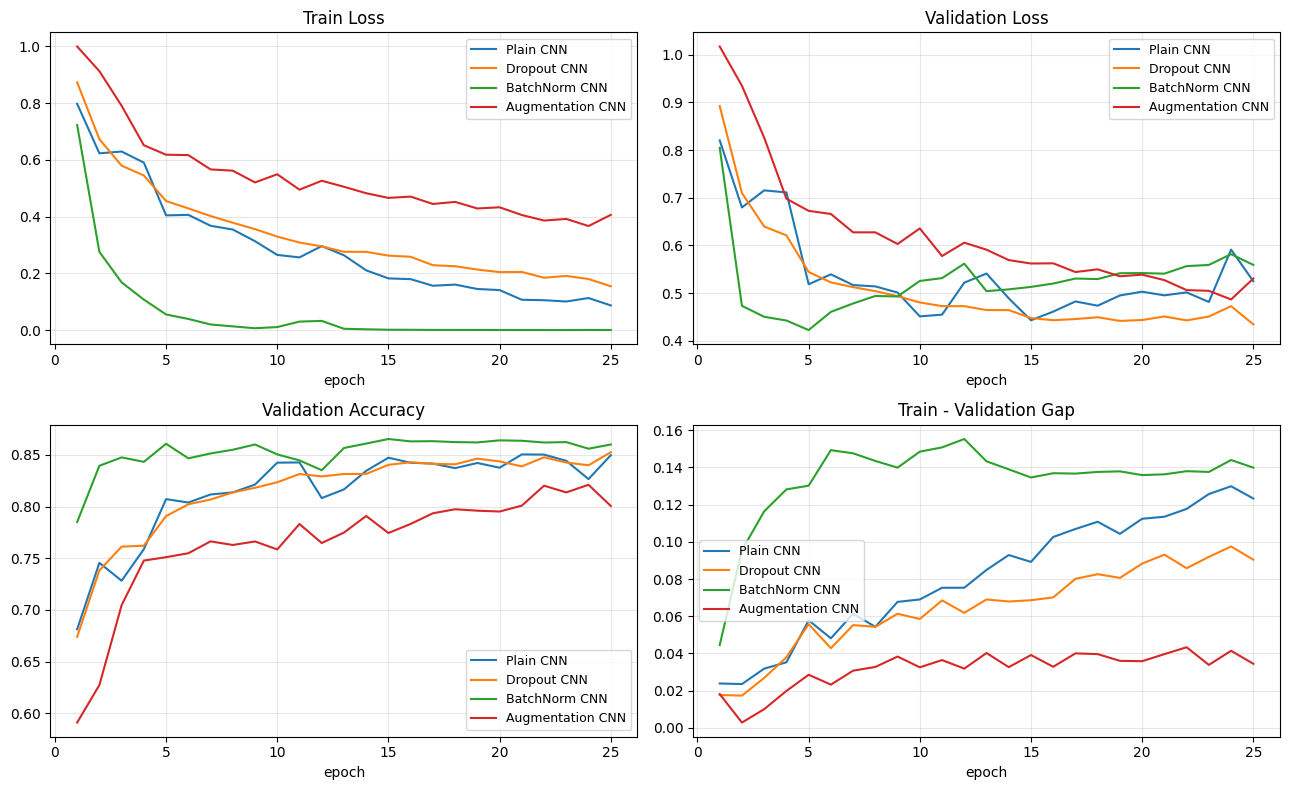

In [5]:
# 답안

# 모델별 결과 비교표 생성
rows = []

for name in results:
    h = results[name]["hist"]
    rows.append({
        "모델": name,
        "학습 정확도": round(h[-1][1], 4),
        "검증 정확도": round(h[-1][3], 4),
        "차이": round(h[-1][1] - h[-1][3], 4),
        "최고 검증": round(max(x[3] for x in h), 4),
        "검증 손실": round(h[-1][2], 4),
        "학습 시간(초)": round(results[name]["time"], 1),
    })

table = pd.DataFrame(rows)
print(table.to_string(index=False))

# 검증 정확도가 가장 높은 모델 확인
best = table.loc[table["검증 정확도"].idxmax(), "모델"]
print(f"\n검증 정확도가 가장 높은 모델: {best}")

# 그래프 범례 설정
labels = {
    "기본 CNN": "Plain CNN",
    "Dropout CNN": "Dropout CNN",
    "BatchNorm CNN": "BatchNorm CNN",
    "데이터 증강 CNN": "Augmentation CNN"
}

# 모델별 학습 곡선 비교
xs = range(1, EPOCHS + 1)
fig, ax = plt.subplots(2, 2, figsize=(13, 8))

for name in results:
    h = results[name]["hist"]
    ax[0, 0].plot(xs, [v[0] for v in h], label=labels[name])
    ax[0, 1].plot(xs, [v[2] for v in h], label=labels[name])
    ax[1, 0].plot(xs, [v[3] for v in h], label=labels[name])
    ax[1, 1].plot(xs, [v[1]-v[3] for v in h], label=labels[name])

titles = ["Train Loss", "Validation Loss",
          "Validation Accuracy", "Train - Validation Gap"]

for a, t in zip(ax.flatten(), titles):
    a.set_title(t)
    a.set_xlabel("epoch")
    a.legend(fontsize=9)
    a.grid(alpha=.3)

plt.tight_layout()
plt.show()


## 문제 4. 가장 좋은 모델 선택과 이유 (20점)
아래 네 가지를 근거로 삼아, 어떤 모델을 고를지와 그 이유를 적으세요.

1. 검증 정확도
2. 학습-검증 차이 (과적합 정도)
3. 학습 시간
4. 오류 이미지에서 관찰한 것

정확도가 가장 높은 모델이 항상 최선은 아닙니다. 판단 근거를 분명히 쓰세요.


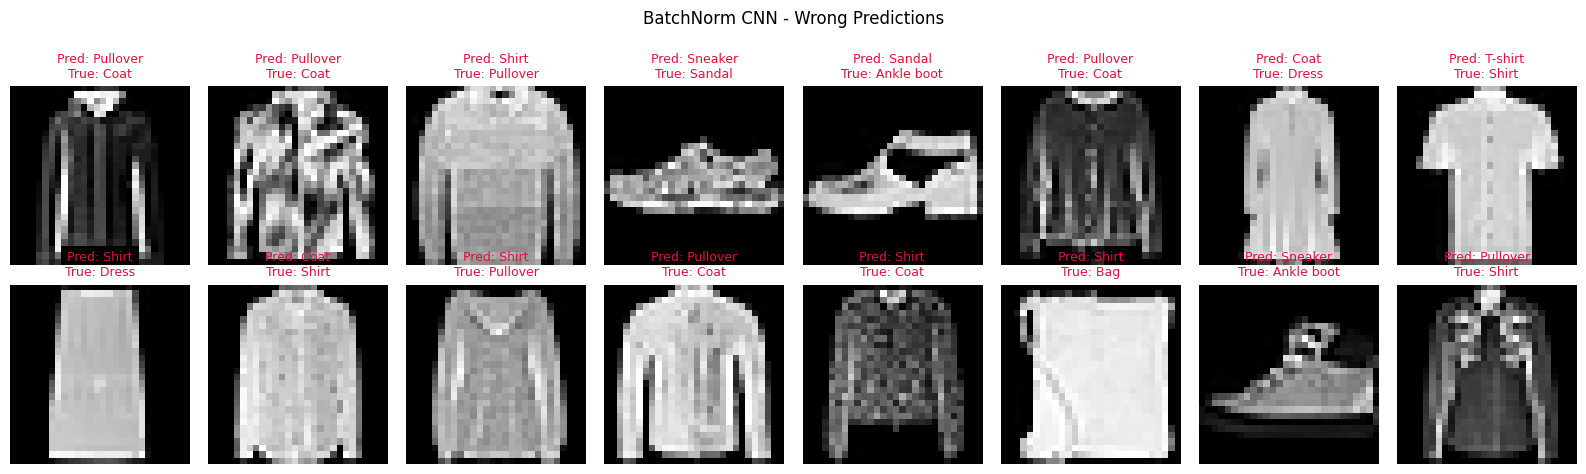

 클래스  기본 CNN  Dropout CNN  BatchNorm CNN  데이터 증강 CNN
 티셔츠   0.807        0.832          0.834       0.821
  바지   0.959        0.971          0.961       0.966
 풀오버   0.624        0.781          0.770       0.835
 드레스   0.880        0.858          0.871       0.910
  코트   0.848        0.808          0.754       0.716
  샌들   0.926        0.947          0.948       0.801
  셔츠   0.580        0.509          0.603       0.144
 운동화   0.963        0.905          0.941       0.959
  가방   0.971        0.953          0.960       0.931
앵클부츠   0.939        0.962          0.959       0.923


In [6]:
# 오류 이미지와 클래스별 정확도 확인 코드

# 이미지 출력용 영어 클래스 이름
classes_en = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat",
              "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

# 검증 정확도가 가장 높은 모델 선택
model = results[best]["model"]
model.eval()

# 잘못 예측한 이미지 수집
imgs, trues, preds = [], [], []

with torch.no_grad():
    for x, y in test_loader:
        p = model(x.to(device)).argmax(dim=1).cpu()
        wrong = p != y

        if wrong.any():
            imgs.append(x[wrong])
            trues.append(y[wrong])
            preds.append(p[wrong])

        if sum(len(t) for t in trues) > 16:
            break

imgs = torch.cat(imgs)
trues = torch.cat(trues)
preds = torch.cat(preds)

# 오류 이미지 16장 출력
fig, axes = plt.subplots(2, 8, figsize=(16, 4.6))

for ax_, i in zip(axes.flatten(), range(16)):
    ax_.imshow(imgs[i].squeeze(), cmap="gray")
    ax_.set_title(
        f"Pred: {classes_en[preds[i]]}\nTrue: {classes_en[trues[i]]}",
        fontsize=9, color="crimson"
    )
    ax_.axis("off")

plt.suptitle(f"{best} - Wrong Predictions", y=1.02)
plt.tight_layout()
plt.show()


# 클래스별 정확도 계산
def per_class(model):
    model.eval()
    correct = torch.zeros(10)
    total = torch.zeros(10)

    with torch.no_grad():
        for x, y in test_loader:
            p = model(x.to(device)).argmax(dim=1).cpu()

            for c in range(10):
                mask = y == c
                total[c] += mask.sum()
                correct[c] += (p[mask] == c).sum()

    return (correct / total).tolist()


# 모델별 클래스 정확도 비교표 출력
cls_df = pd.DataFrame({"클래스": CLASSES})

for name in results:
    cls_df[name] = [
        round(v, 3) for v in per_class(results[name]["model"])
    ]

print(cls_df.to_string(index=False))


**선택한 모델:BatchNorm CNN**

**이유:**

1.검증 정확도가 86.01%, 최고 검증 정확도가 86.54%로 실험한 모델 중 가장 높은 성능을 보였다.

2.학습-검증 정확도 차이는 13.99%p로 과적합이 나타났다. Dropout CNN보다 과적합 완화 효과는 낮았지만, 검증 정확도를 우선하여 선택하였다.

3.학습 시간은 40.5초로 실험한 모델 중 가장 짧았다.

4.오류 이미지를 확인한 결과 코트, 풀오버, 셔츠처럼 형태가 비슷한 의류에서 오분류가 발생하였다. 특히 셔츠의 정확도가 60.3%로 나타나 유사한 의류를 구분하는 데 한계가 있음을 확인하였다.


## 문제 5. 실험에서 배운 것 (보너스)
효과가 없었거나 오히려 나빠진 설정이 있었다면 무엇이고 왜 그랬는지 적으세요.


**답 : 데이터 증강을 적용한 모델은 학습-검증 정확도 차이가 12.33%p에서 3.44%p로 감소했지만, 검증 정확도도 84.97%에서 80.06%로 감소하였다. 회전, 좌우 반전, 이동 및 크기 변환을 함께 적용하면서 이미지의 주요 특징을 학습하기 어려워졌을 가능성이 있다. 이를 통해 데이터 증강이 항상 성능을 향상시키는 것은 아니며, 데이터 특성에 맞는 변형 방법과 강도를 설정해야 한다는 것을 알게 되었다.**
